<a href="https://colab.research.google.com/github/vragarwal/FDS-Results/blob/main/vradhi%20exp%206%20fds.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io

In [2]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("V_S_DATA SET_CLIMATE.csv")

print(df.head())

Saving V_S_DATA SET_CLIMATE.csv to V_S_DATA SET_CLIMATE.csv
       country  longitude        timezone      last_updated  \
0  Afghanistan      69.18      Asia/Kabul  16-05-2024 13:15   
1      Albania      19.82   Europe/Tirane  16-05-2024 10:45   
2      Algeria       3.05  Africa/Algiers  16-05-2024 09:45   
3      Andorra       1.52  Europe/Andorra  16-05-2024 10:45   
4       Angola      13.23   Africa/Luanda  16-05-2024 09:45   

   temperature_celsius condition_text  wind_kph  wind_degree wind_direction  \
0                 26.6  Partly Cloudy      13.3          338            NNW   
1                 19.0  Partly cloudy      11.2          320             NW   
2                 23.0          Sunny      15.1          280              W   
3                  6.3  Light drizzle      11.9          215             SW   
4                 26.0  Partly cloudy      13.0          150            SSE   

   precip_mm  humidity  visibility_km  gust_mph  air_quality_Ozone  \
0        0.0    

In [3]:
target_col = 'temperature_celsius'

print(f"Min : {df[target_col].min()}")
print(f"Max : {df[target_col].max()}")
print(f"Mean : {df[target_col].mean():.4f}")
print(f"Std : {df[target_col].std():.4f}")

Min : -29.8
Max : 79.3
Mean : 21.3828
Std : 9.4642


In [4]:
min_val = df[target_col].min()
max_val = df[target_col].max()
df['temperature_min_max'] = (df[target_col] - min_val) / (max_val - min_val)

In [6]:
mean_val = df[target_col].mean()
std_val = df[target_col].std()
df['temperature_z_score'] = (df[target_col] - mean_val) / std_val

In [7]:
max_abs_val = np.max(np.abs(df[target_col]))
j = int(np.ceil(np.log10(max_abs_val))) if max_abs_val > 0 else 1
df['temperature_decimal_scaled'] = df[target_col] / (10 ** j)

print(df[[target_col, 'temperature_min_max', 'temperature_z_score', 'temperature_decimal_scaled']].head(10))

   temperature_celsius  temperature_min_max  temperature_z_score  \
0                 26.6             0.516957             0.551258   
1                 19.0             0.447296            -0.251770   
2                 23.0             0.483960             0.170876   
3                  6.3             0.330889            -1.593673   
4                 26.0             0.511457             0.487861   
5                 26.0             0.511457             0.487861   
6                  8.0             0.346471            -1.414048   
7                 19.0             0.447296            -0.251770   
8                  9.0             0.355637            -1.308387   
9                 16.0             0.419798            -0.568755   

   temperature_decimal_scaled  
0                       0.266  
1                       0.190  
2                       0.230  
3                       0.063  
4                       0.260  
5                       0.260  
6                       0.0

In [8]:
def kmeans_discretization(data, k=3, max_iter=100):
    np.random.seed(42)
    centroids = np.random.choice(data, k, replace=False)

    for _ in range(max_iter):
        distances = np.abs(data[:, np.newaxis] - centroids)
        labels = np.argmin(distances, axis=1)
        new_centroids = np.array([
            data[labels == i].mean() if np.any(labels == i) else centroids[i]
            for i in range(k)
        ])

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return labels, centroids

labels, centroids = kmeans_discretization(df[target_col].values)
order = np.argsort(centroids)
label_map = {old: f"Cluster_{new+1}" for new, old in enumerate(order)}
df['temperature_cluster'] = [label_map[i] for i in labels]

print(df[[target_col, 'temperature_cluster']].head(10))

   temperature_celsius temperature_cluster
0                 26.6           Cluster_3
1                 19.0           Cluster_2
2                 23.0           Cluster_2
3                  6.3           Cluster_1
4                 26.0           Cluster_3
5                 26.0           Cluster_3
6                  8.0           Cluster_1
7                 19.0           Cluster_2
8                  9.0           Cluster_1
9                 16.0           Cluster_2


In [9]:
print(df.groupby('temperature_cluster')[target_col].agg(['count', 'min', 'max', 'mean']))

                     count   min   max       mean
temperature_cluster                              
Cluster_1            28715 -29.8  12.7   5.730611
Cluster_2            56979  12.8  24.4  19.833579
Cluster_3            69642  24.5  79.3  29.104079


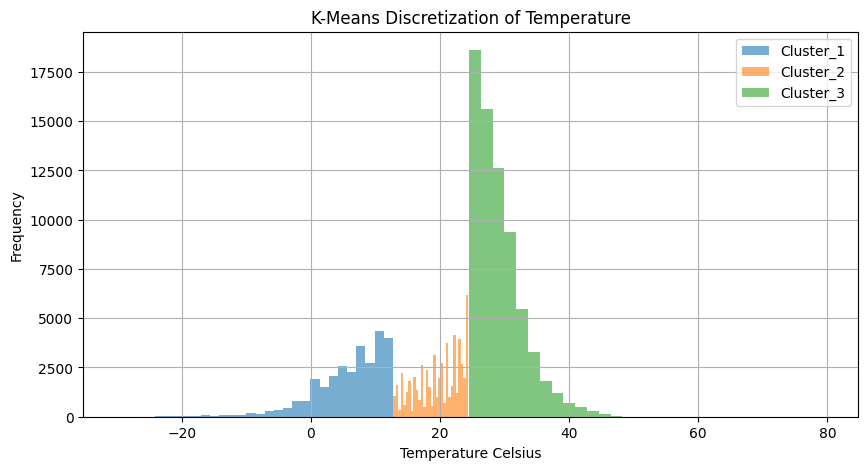

In [10]:
plt.figure(figsize=(10, 5))

for cluster in sorted(df['temperature_cluster'].unique()):
    subset = df[df['temperature_cluster'] == cluster]
    plt.hist(subset[target_col], bins=30, alpha=0.6, label=cluster)

plt.xlabel('Temperature Celsius')
plt.ylabel('Frequency')
plt.title('K-Means Discretization of Temperature')
plt.legend()
plt.grid(True)
plt.show()